# Progetto: Segmentazione ECG con PhysioNet
## Fase 1: Setup, Caricamento Dati e Preprocessing

Questo notebook gestisce il caricamento dei dati pre-elaborati da MATLAB (`QTData_ready.mat`), l'applicazione di una tecnica di *sliding window* per uniformare le dimensioni dei tracciati e la preparazione dei tensori per l'addestramento della rete neurale (Train/Test split e One-Hot Encoding).
Al fine di mantenere il codice pulito e privo di ridondanze, in questo blocco iniziale vengono centralizzate tutte le costanti globali e gli iperparametri di training.

In [1]:
import os
import numpy as np
import scipy.io as sio
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

# ==========================================
# 1. Configurazione e Iperparametri Globali
# ==========================================
FILENAME = "QTData_ready.mat"
WINDOW_SIZE = 1000  # 4 secondi a 250Hz, definisce il campo recettivo della rete
NUM_CLASSES = 4     # 0 = n/a, 1 = P, 2 = QRS, 3 = T
TEST_SIZE = 0.20
RANDOM_STATE = 42

# --- Iperparametri di Training Centralizzati ---
LEARNING_RATE = 1e-3
BATCH_SIZE = 32
EPOCHS = 50

# Risoluzione dinamica del percorso (gestisce l'avvio da /notebooks o dalla root)
current_dir = os.getcwd()
if os.path.exists(os.path.join(current_dir, "data", FILENAME)):
    DATA_PATH = os.path.join(current_dir, "data", FILENAME)
elif os.path.exists(os.path.join(current_dir, "..", "data", FILENAME)):
    DATA_PATH = os.path.join(current_dir, "..", "data", FILENAME)
else:
    # Fallback manuale nel caso in cui la struttura non corrisponda
    DATA_PATH = os.path.join("data", FILENAME)
    print("⚠️ Attenzione: Cartella 'data' non trovata in automatico. Verrà usato il percorso relativo base.")
    
# Creazione preventiva della cartella per i modelli e definizione path
os.makedirs("models", exist_ok=True)
MODEL_SAVE_PATH = os.path.join("models", "best_unet_ecg_model.keras")

## Funzioni Core

Definiamo le funzioni per il caricamento sicuro dal formato `.mat` e per l'applicazione della *sliding window*. 
**Nota architetturale:** La logica di caricamento gestisce le particolarità dei cell array esportati da MATLAB, assicurando che la forma del segnale sia sempre $(time\_steps, channels)$.

In [2]:
# ==========================================
# 2. Logica di Caricamento e Preprocessing
# ==========================================

def load_matlab_data(filepath):
    """
    Carica i dati pre-elaborati da MATLAB e li standardizza in liste NumPy.
    Si aspetta le chiavi 'X' (segnali) e 'Y' (etichette).
    """
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Il file non esiste nel percorso risolto: {filepath}")
        
    mat_data = sio.loadmat(filepath)
    
    # Estrazione dei cell array e appiattimento della struttura a oggetti
    X_raw = mat_data.get('X', []).flatten()
    Y_raw = mat_data.get('Y', []).flatten()
    
    signals, labels = [], []
    
    for sig, lab in zip(X_raw, Y_raw):
        # Rimuove dimensioni vuote aggiunte da MATLAB/scipy (es. (1, 225000) -> (225000,))
        sig = np.squeeze(sig)
        lab = np.squeeze(lab)
        
        # Gestione dimensionale: se la shape è (2, N), trasponiamo a (N, 2)
        if sig.ndim == 2 and sig.shape[0] == 2 and sig.shape[1] > 2:
            sig = sig.T
            
        # Assicuriamoci che le etichette siano 1D
        if lab.ndim > 1:
            lab = lab.flatten()
            
        signals.append(sig)
        labels.append(lab)
        
    return signals, labels


def apply_sliding_window(signals, labels, window_size):
    """
    Suddivide i segnali di lunghezza variabile in finestre fisse.
    I campioni residui in coda al tracciato vengono scartati.
    """
    X_list, Y_list = [], []
    
    for patient_signal, patient_label in zip(signals, labels):
        num_samples = patient_signal.shape[0]
        num_windows = num_samples // window_size
        
        # Troncamento per ottenere una lunghezza multipla della finestra
        truncated_signal = patient_signal[:num_windows * window_size, :]
        truncated_label = patient_label[:num_windows * window_size]
        
        # Reshape dimensionale: (numero_finestre, 1000, 2 canali)
        X_windows = truncated_signal.reshape((num_windows, window_size, patient_signal.shape[1]))
        Y_windows = truncated_label.reshape((num_windows, window_size))
        
        X_list.append(X_windows)
        Y_list.append(Y_windows)
        
    # Concatenazione in array globali
    X_global = np.concatenate(X_list, axis=0)
    Y_global = np.concatenate(Y_list, axis=0)
    
    return X_global, Y_global

## Esecuzione Pipeline

Eseguiamo l'estrazione, il taglio in finestre, lo split in set di addestramento/test e la codifica delle etichette (One-Hot), sfruttando le costanti globali precedentemente definite.

In [3]:
# ==========================================
# 3. Esecuzione Pipeline
# ==========================================

print(f"--- Avvio Pipeline ECG con dataset in: {DATA_PATH} ---")

# 1. Caricamento
try:
    raw_signals, raw_labels = load_matlab_data(DATA_PATH)
    print(f"[OK] Dati caricati. Numero di pazienti elaborati: {len(raw_signals)}")
    
    # 2. Sliding Window
    X_data, Y_data = apply_sliding_window(raw_signals, raw_labels, WINDOW_SIZE)
    print(f"[OK] Shape dopo Sliding Window -> X: {X_data.shape}, Y: {Y_data.shape}")
    
    # 3. Train/Test Split (A livello di finestra)
    X_train, X_test, y_train, y_test = train_test_split(
        X_data, Y_data, 
        test_size=TEST_SIZE, 
        random_state=RANDOM_STATE
    )
    print(f"[OK] Shape dopo Train/Test Split -> X_train: {X_train.shape}, X_test: {X_test.shape}")
    
    # 4. One-Hot Encoding per Categorical Crossentropy
    y_train_encoded = to_categorical(y_train, num_classes=NUM_CLASSES)
    y_test_encoded = to_categorical(y_test, num_classes=NUM_CLASSES)
    print(f"[OK] Shape dopo One-Hot Encoding -> y_train_encoded: {y_train_encoded.shape}, y_test_encoded: {y_test_encoded.shape}")
    
    print("\n--- Preprocessing completato con successo. Tensori pronti! ---")

except FileNotFoundError as e:
    print(f"\n[ERRORE FATALE]: {e}")
    print("Assicurati che il file QTData_ready.mat sia stato copiato nella cartella 'data' del progetto.")
except Exception as e:
    print(f"\n[ERRORE INASPETTATO]: {e}")

--- Avvio Pipeline ECG con dataset in: c:\Users\simon\Downloads\FDL_Project\notebooks\..\data\QTData_ready.mat ---
[OK] Dati caricati. Numero di pazienti elaborati: 105
[OK] Shape dopo Sliding Window -> X: (23573, 1000, 2), Y: (23573, 1000)
[OK] Shape dopo Train/Test Split -> X_train: (18858, 1000, 2), X_test: (4715, 1000, 2)
[OK] Shape dopo One-Hot Encoding -> y_train_encoded: (18858, 1000, 4), y_test_encoded: (4715, 1000, 4)

--- Preprocessing completato con successo. Tensori pronti! ---


## Fase 2: Architettura del Modello (U-Net 1D)

Per questo task di segmentazione densa a 4 classi (N/A, P, QRS, T), implementiamo un'architettura **U-Net 1D**. 
* **L'Encoder** (contrazione) estrae le feature morfologiche dell'ECG.
* **Il Decoder** (espansione) ripristina la dimensionalità originale (1000 campioni).
* Le **Skip Connections** concatenate aiutano la rete a non perdere le coordinate temporali esatte delle onde durante l'upsampling.

In [4]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, UpSampling1D, Concatenate, Dropout
from tensorflow.keras.optimizers import Adam

# ==========================================
# 4. Costruzione Architettura U-Net 1D
# ==========================================

def build_unet_1d(input_shape, num_classes):
    inputs = Input(shape=input_shape)
    
    # --- ENCODER (Discesa) ---
    # Blocco 1
    c1 = Conv1D(32, kernel_size=5, activation='relu', padding='same')(inputs)
    c1 = Conv1D(32, kernel_size=5, activation='relu', padding='same')(c1)
    p1 = MaxPooling1D(pool_size=2)(c1) # Shape: (500, 32)
    
    # Blocco 2
    c2 = Conv1D(64, kernel_size=5, activation='relu', padding='same')(p1)
    c2 = Conv1D(64, kernel_size=5, activation='relu', padding='same')(c2)
    p2 = MaxPooling1D(pool_size=2)(c2) # Shape: (250, 64)
    
    # --- BOTTLENECK ---
    # Blocco 3 (Nessun pooling)
    c3 = Conv1D(128, kernel_size=5, activation='relu', padding='same')(p2)
    c3 = Conv1D(128, kernel_size=5, activation='relu', padding='same')(c3)
    # Aggiungiamo un po' di Dropout per regolarizzazione
    drop3 = Dropout(0.3)(c3) # Shape: (250, 128)
    
    # --- DECODER (Risalita) ---
    # Blocco 4
    u4 = UpSampling1D(size=2)(drop3) # Shape: (500, 128)
    concat4 = Concatenate()([u4, c2]) # Skip connection con c2
    c4 = Conv1D(64, kernel_size=5, activation='relu', padding='same')(concat4)
    c4 = Conv1D(64, kernel_size=5, activation='relu', padding='same')(c4)
    
    # Blocco 5
    u5 = UpSampling1D(size=2)(c4) # Shape: (1000, 64)
    concat5 = Concatenate()([u5, c1]) # Skip connection con c1
    c5 = Conv1D(32, kernel_size=5, activation='relu', padding='same')(concat5)
    c5 = Conv1D(32, kernel_size=5, activation='relu', padding='same')(c5)
    
    # --- OUTPUT LAYER ---
    # Classificazione densa: 4 filtri (uno per classe) e softmax per ottenere probabilità
    outputs = Conv1D(num_classes, kernel_size=1, activation='softmax', padding='same')(c5)
    
    model = Model(inputs=inputs, outputs=outputs, name="UNet_1D_ECG")
    return model

# Istanziamo il modello sfruttando le costanti globali WINDOW_SIZE e NUM_CLASSES
input_shape = (WINDOW_SIZE, X_train.shape[2]) # (1000, 2)
model = build_unet_1d(input_shape, NUM_CLASSES)

# Riepilogo dell'architettura
model.summary()

Model: "UNet_1D_ECG"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1000, 2)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 1000, 32)  │        352 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 1000, 32)  │      5,152 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 500, 32)   │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 500, 64)   │     10,304 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 500, 64)   │     20,544 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 250, 64)   │          0 │ conv1d_3[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 250, 128)  │     41,088 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 250, 128)  │     82,048 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 250, 128)  │          0 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling1d       │ (None, 500, 128)  │          0 │ dropout[0][0]     │
│ (UpSampling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 500, 192)  │          0 │ up_sampling1d[0]… │
│ (Concatenate)       │                   │            │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 500, 64)   │     61,504 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 500, 64)   │     20,544 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling1d_1     │ (None, 1000, 64)  │          0 │ conv1d_7[0][0]    │
│ (UpSampling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 1000, 96)  │          0 │ up_sampling1d_1[… │
│ (Concatenate)       │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 1000, 32)  │     15,392 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 1000, 32)  │      5,152 │ conv1d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 1000, 4)   │        132 │ conv1d_9[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 262,212 (1.00 MB)

 Trainable params: 262,212 (1.00 MB)

 Non-trainable params: 0 (0.00 B)

# ==========================================
# 5. Compilazione del Modello
# ==========================================

# Il LEARNING_RATE è ora importato globalmente dalla Cella di Setup
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("[OK] Modello compilato e pronto per il training.")

In [5]:
# ==========================================
# 5. Compilazione del Modello
# ==========================================

# Il LEARNING_RATE è ora importato globalmente dalla Cella di Setup
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("[OK] Modello compilato e pronto per il training.")

[OK] Modello compilato e pronto per il training.


## Fase 3: Gestione dello Sbilanciamento delle Classi (Sample Weights)

I segnali ECG sono intrinsecamente sbilanciati: la classe 0 (N/A o linea isoelettrica) occupa la maggior parte del tracciato, mentre le onde P, QRS e T appaiono solo in intervalli ristretti.
Per evitare che il modello impari a predire solo la classe maggioritaria, calcoliamo i pesi inversamente proporzionali alla frequenza delle classi e generiamo una matrice di `sample_weight` da passare a Keras durante il training.

In [6]:
from sklearn.utils.class_weight import compute_class_weight

# ==========================================
# 6. Calcolo dei Pesi e Generazione Sample Weights
# ==========================================

print("--- Calcolo del bilanciamento delle classi ---")

# Appiattiamo il vettore y_train originale per calcolare la frequenza globale delle classi
y_train_flat = y_train.flatten()

# Calcolo dei pesi per ciascuna delle 4 classi
classes = np.unique(y_train_flat)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_flat)
class_weights_dict = dict(zip(classes, weights))

print("Pesi calcolati per singola classe:")
for cls, weight in class_weights_dict.items():
    mapping = {0: "N/A (Isoelettrica)", 1: "Onda P", 2: "Complesso QRS", 3: "Onda T"}
    print(f" - Classe {cls} ({mapping[cls]}): {weight:.4f}")

# Creazione della matrice sample_weight per il set di addestramento
# Mappiamo ogni etichetta temporale al suo rispettivo peso
sample_weights_train = np.vectorize(class_weights_dict.get)(y_train)

print(f"\n[OK] Matrice sample_weight creata. Shape: {sample_weights_train.shape}")

--- Calcolo del bilanciamento delle classi ---
Pesi calcolati per singola classe:
 - Classe 0 (N/A (Isoelettrica)): 0.4911
 - Classe 1 (Onda P): 2.3566
 - Classe 2 (Complesso QRS): 1.7976
 - Classe 3 (Onda T): 1.0172

[OK] Matrice sample_weight creata. Shape: (18858, 1000)


## Fase 4: Configurazione dei Callbacks di Keras

Come richiesto dalle specifiche d'esame, implementiamo i Callbacks per ottimizzare il processo di addestramento:
1. **EarlyStopping**: Interrompe il training se la `val_loss` smette di migliorare per 10 epoche, ripristinando i pesi migliori ed evitando l'overfitting.
2. **ModelCheckpoint**: Salva automaticamente il miglior modello sul disco nel formato nativo di Keras (`.keras`) all'interno della cartella `/models`.
3. **ReduceLROnPlateau**: Riduce dinamicamente il Learning Rate se il modello entra in un plateau di apprendimento, permettendo una convergenza più fine.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# ==========================================
# 7. Definizione dei Callbacks
# ==========================================

# MODEL_SAVE_PATH è ora importato globalmente dalla Cella di Setup
callbacks_list = [
    # Early Stopping per evitare Overfitting (Richiesto da E04)
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    
    # Salvataggio automatico del miglior modello (Richiesto per la consegna del progetto)
    ModelCheckpoint(
        filepath=MODEL_SAVE_PATH,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    
    # Riduzione dinamica del Learning Rate (Ottimizzazione avanzata)
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

print(f"[OK] Callbacks configurati. Il modello migliore verrà salvato in: {MODEL_SAVE_PATH}")

[OK] Callbacks configurati. Il modello migliore verrà salvato in: models\best_unet_ecg_model.keras


## Fase 5: Addestramento del Modello

Avviamo il processo di `model.fit()`. Passiamo i dati codificati in One-Hot, integriamo i `sample_weight` per gestire lo sbilanciamento e applichiamo la lista dei nostri `callbacks`. Epoche e dimensione del batch sono controllate centralmente dai parametri globali definiti nel Setup iniziale.

In [16]:
# ==========================================
# 8. Esecuzione dell'Addestramento (Training)
# ==========================================

# EPOCHS e BATCH_SIZE sono ora importati globalmente dalla Cella di Setup

print(f"--- Avvio dell'Addestramento del Modello U-Net 1D (Epoche: {EPOCHS}, Batch Size: {BATCH_SIZE}) ---")

history = model.fit(
    X_train, 
    y_train_encoded,
    validation_data=(X_test, y_test_encoded),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    sample_weight=sample_weights_train, # Bilanciamento delle classi applicato qui
    callbacks=callbacks_list,           # Callbacks d'esame applicati qui
    verbose=1
)

print("\n--- Addestramento completato! ---")

--- Avvio dell'Addestramento del Modello U-Net 1D (Epoche: 50, Batch Size: 32) ---
Epoch 1/50
589/590 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.4741 - loss: 2.0552
Epoch 1: val_loss improved from None to 0.50677, saving model to models\best_unet_ecg_model.keras

Epoch 1: finished saving model to models\best_unet_ecg_model.keras
590/590 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.6204 - loss: 0.9891 - val_accuracy: 0.8052 - val_loss: 0.5068 - learning_rate: 0.0010
Epoch 2/50
589/590 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8141 - loss: 0.4021
Epoch 2: val_loss improved from 0.50677 to 0.36494, saving model to models\best_unet_ecg_model.keras

Epoch 2: finished saving model to models\best_unet_ecg_model.keras
590/590 ━━━━━━━━━━━━━━━━━━━━ 25s 42ms/step - accuracy: 0.8271 - loss: 0.3713 - val_accuracy: 0.8569 - val_loss: 0.3649 - learning_rate: 0.0010
Epoch 3/50
589/590 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8554 - loss: 0.3083
Epoch 3: val_loss improved from 0.3

## Fase 6: Esportazione della Training History

Al fine di garantire la riproducibilità e permettere un'analisi strutturata a posteriori delle performance del modello, esportiamo tutte le metriche registrate durante il training (Loss, Validation Loss, Accuracy, Validation Accuracy, ecc.). 
I dati vengono salvati sia in formato strutturato `.json` che in formato tabellare `.csv` all'interno della cartella dedicata `logs/`.

In [ ]:
import json
import csv

# ==========================================
# 9. Esportazione Log di Addestramento
# ==========================================

print("--- Avvio esportazione metriche di training ---")

# Creazione della cartella dedicata ai log se non esiste
os.makedirs("logs", exist_ok=True)
JSON_LOG_PATH = os.path.join("logs", "training_history.json")
CSV_LOG_PATH = os.path.join("logs", "training_history.csv")

# Keras memorizza i log in un dizionario (history.history) in formato numpy.float32.
# Per una corretta serializzazione in JSON, convertiamo esplicitamente in float Python standard.
history_dict = {key: [float(val) for val in values] for key, values in history.history.items()}

# 1. Salvataggio in formato JSON
with open(JSON_LOG_PATH, 'w') as json_file:
    json.dump(history_dict, json_file, indent=4)
print(f"[OK] Training history salvata in formato JSON: {JSON_LOG_PATH}")

# 2. Salvataggio in formato CSV
with open(CSV_LOG_PATH, 'w', newline='') as csv_file:
    writer = csv.writer(csv_file)
    
    # Intestazioni: 'epoch' + tutte le chiavi presenti nella history (loss, accuracy, ecc.)
    keys = list(history_dict.keys())
    writer.writerow(['epoch'] + keys)
    
    # Scrittura dinamica delle righe per ogni epoca
    num_epochs_trained = len(history_dict[keys[0]])
    for i in range(num_epochs_trained):
        row = [i + 1] + [history_dict[k][i] for k in keys]
        writer.writerow(row)

print(f"[OK] Training history salvata in formato CSV: {CSV_LOG_PATH}")
print("--- Esportazione completata con successo! ---")

## Phase 7: Quantitative Evaluation

In this phase, we evaluate the real performance of the 1D U-Net on the unseen Test Set.
We load the best model saved by the `ModelCheckpoint` and compute the **Classification Report** and the **Confusion Matrix** on a pixel-by-pixel (sample-by-sample) basis to understand how the network behaves on each individual class.

--- Valutazione Quantitativa sul Test Set ---
[OK] Miglior modello caricato da models\best_unet_ecg_model.keras
Generazione predizioni in corso...
148/148 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step

=== Classification Report ===
              precision    recall  f1-score   support

      0: N/A       0.96      0.92      0.94   2395701
        1: P       0.87      0.95      0.91    499948
      2: QRS       0.95      0.98      0.97    654661
        3: T       0.91      0.94      0.92   1164690

    accuracy                           0.94   4715000
   macro avg       0.92      0.95      0.93   4715000
weighted avg       0.94      0.94      0.94   4715000


=== Generazione Confusion Matrix ===


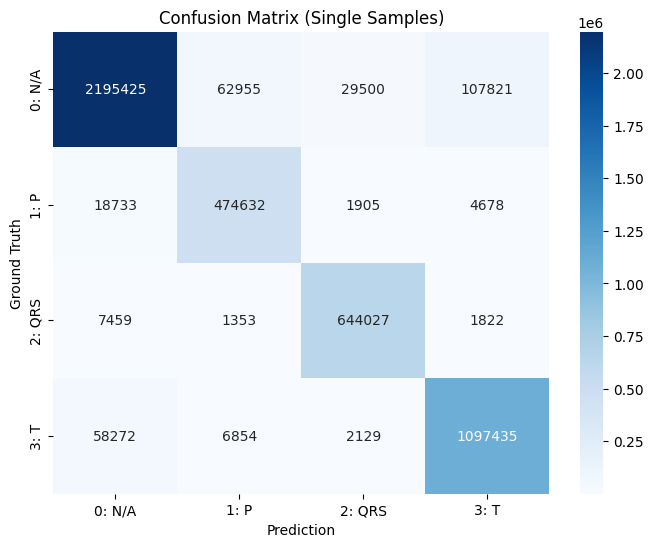

In [13]:
# ==========================================
# 10. Quantitative Evaluation
# ==========================================
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Valutazione Quantitativa sul Test Set ---")

# Carichiamo il miglior modello salvato precedentemente
best_model = load_model(MODEL_SAVE_PATH)
print(f"[OK] Miglior modello caricato da {MODEL_SAVE_PATH}")

# Generazione delle predizioni (BATCH_SIZE è importato dalle costanti globali)
print("Generazione predizioni in corso...")
y_pred_prob = best_model.predict(X_test, batch_size=BATCH_SIZE)

# Convertiamo le probabilità (One-Hot) in classi intere (0, 1, 2, 3)
y_pred_classes = np.argmax(y_pred_prob, axis=-1)
y_test_classes = np.argmax(y_test_encoded, axis=-1)

# Per le metriche classiche, "appiattiamo" i tensori da (N, 1000) a (N*1000,)
# in modo da valutare la predizione su ogni singolo istante temporale
y_pred_flat = y_pred_classes.flatten()
y_test_flat = y_test_classes.flatten()

class_names = ['0: N/A', '1: P', '2: QRS', '3: T']

# 1. Classification Report
print("\n=== Classification Report ===")
print(classification_report(y_test_flat, y_pred_flat, target_names=class_names))

# 2. Confusion Matrix
print("\n=== Generazione Confusion Matrix ===")
cm = confusion_matrix(y_test_flat, y_pred_flat)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)

# --- ELEMENTI GRAFICI IN INGLESE ---
plt.title('Confusion Matrix (Single Samples)')
plt.ylabel('Ground Truth')
plt.xlabel('Prediction')
plt.show()

## Phase 8: Qualitative Evaluation (Visualization)

We select a random window from the Test Set and visually compare the real physiological segmentation (Ground Truth) against the regions predicted by our U-Net model. Background colors indicate the presence of the different cardiac waves.

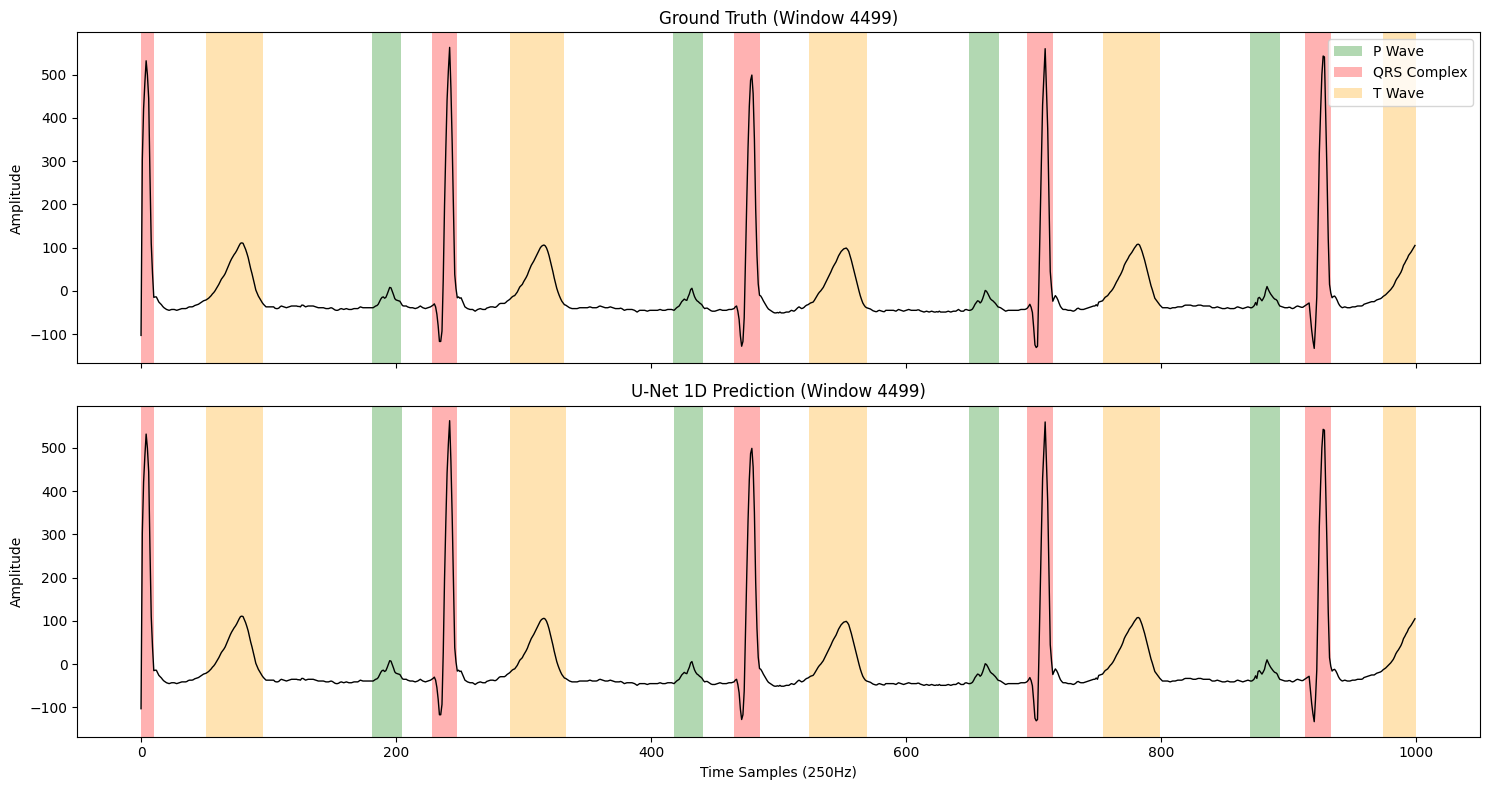

In [14]:
import random
from matplotlib.patches import Patch

# ==========================================
# 11. Qualitative Evaluation (Visualization)
# ==========================================

def plot_ecg_segmentation(x_signal, y_true, y_pred, window_index):
    """
    Traccia il segnale ECG con sfondi colorati che rappresentano 
    le zone segmentate per Ground Truth (sopra) e Predizione (sotto).
    """
    time_steps = np.arange(x_signal.shape[0])
    ecg_lead_1 = x_signal[:, 0] # Prendiamo il primo canale
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
    
    # Mappa dei colori per le classi: P (Verde), QRS (Rosso), T (Arancione)
    colors = {1: 'green', 2: 'red', 3: 'orange'}
    
    # --- PLOT 1: GROUND TRUTH ---
    ax1.plot(time_steps, ecg_lead_1, color='black', linewidth=1)
    
    # --- TRADUZIONE IN INGLESE ---
    ax1.set_title(f'Ground Truth (Window {window_index})')
    ax1.set_ylabel('Amplitude')
    
    for c in [1, 2, 3]:
        regions = np.where(y_true == c)[0]
        for r in regions:
            ax1.axvspan(r, r+1, color=colors[c], alpha=0.3, lw=0)
            
    # --- PLOT 2: PREDICTION ---
    ax2.plot(time_steps, ecg_lead_1, color='black', linewidth=1)
    
    # --- TRADUZIONE IN INGLESE ---
    ax2.set_title(f'U-Net 1D Prediction (Window {window_index})')
    ax2.set_xlabel('Time Samples (250Hz)')
    ax2.set_ylabel('Amplitude')
    
    for c in [1, 2, 3]:
        regions = np.where(y_pred == c)[0]
        for r in regions:
            ax2.axvspan(r, r+1, color=colors[c], alpha=0.3, lw=0)
            
    # --- TRADUZIONE LEGENDA IN INGLESE ---
    legend_elements = [
        Patch(facecolor='green', alpha=0.3, label='P Wave'),
        Patch(facecolor='red', alpha=0.3, label='QRS Complex'),
        Patch(facecolor='orange', alpha=0.3, label='T Wave')
    ]
    ax1.legend(handles=legend_elements, loc='upper right')
    
    plt.tight_layout()
    plt.show()

# Visualizzazione di un campione casuale
random_idx = random.randint(0, X_test.shape[0] - 1)
plot_ecg_segmentation(X_test[random_idx], y_test_classes[random_idx], y_pred_classes[random_idx], random_idx)

## Phase 9: Model Confidence and Uncertainty Analysis

In medical domains, understanding *where* the model is uncertain is as critical as the final prediction. In this section, we analyze the raw probability distributions outputted by the Softmax layer before the `argmax` classification. 
By plotting the continuous probabilities of the cardiac waves, we can visualize the model's confidence and properly investigate the boundary ambiguity (especially regarding the T-Wave's asymptotic decay).

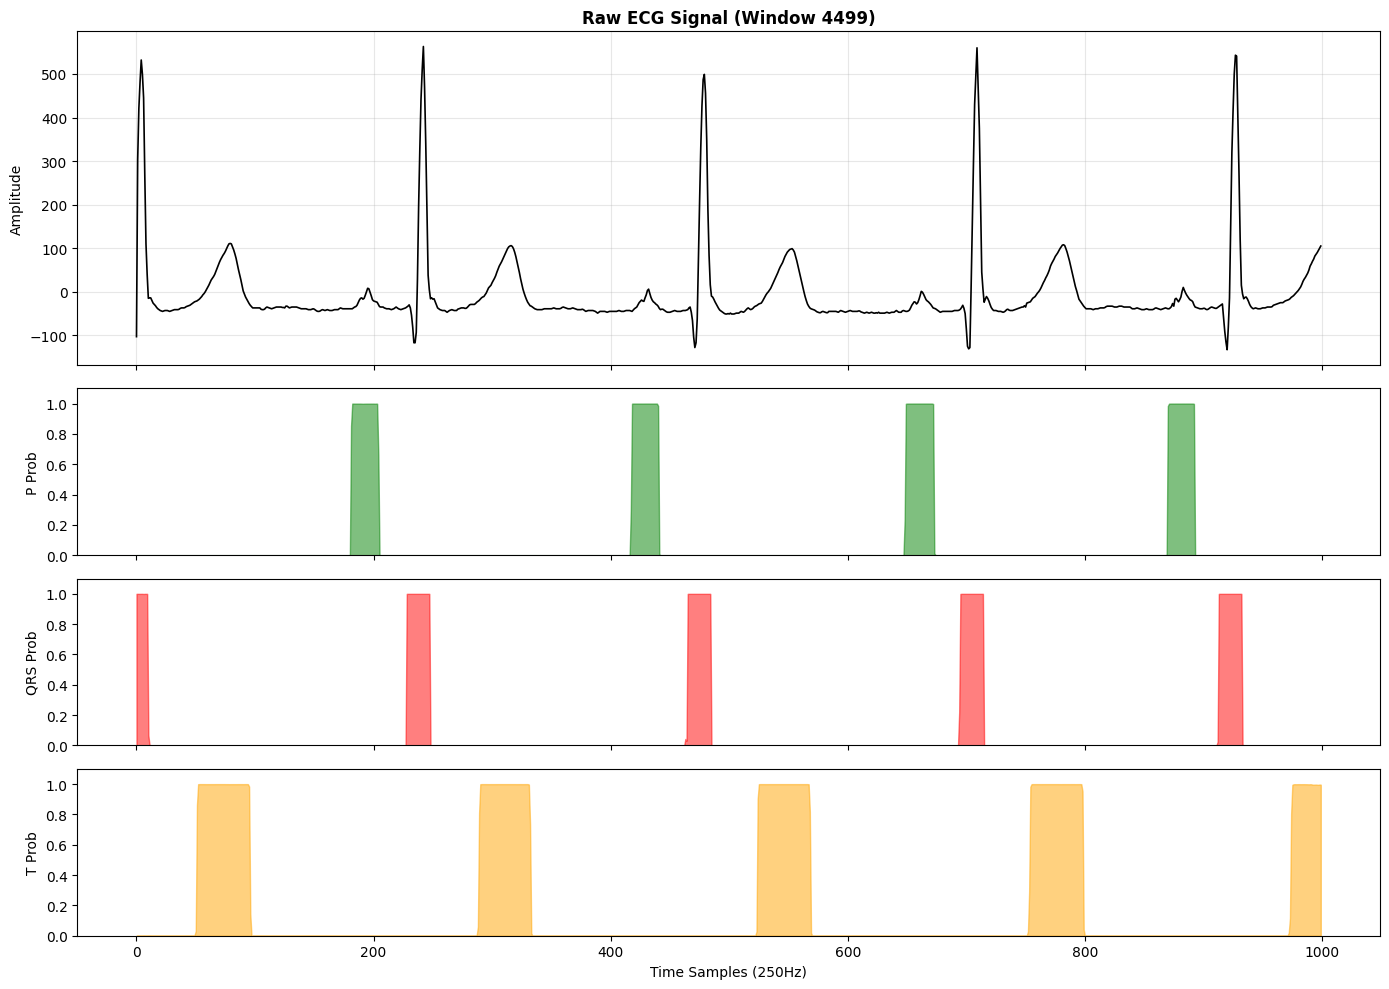

In [15]:
# ==========================================
# 12. Model Confidence & Uncertainty Analysis
# ==========================================
import matplotlib.pyplot as plt
import numpy as np

def plot_softmax_confidence(x_signal, y_pred_probabilities, window_index):
    """
    Traccia il segnale ECG in alto e le distribuzioni di probabilità Softmax
    per le tre onde cardiache (P, QRS, T) nei subplot inferiori.
    """
    time_steps = np.arange(x_signal.shape[0])
    ecg_signal = x_signal[:, 0]
    
    # Estraiamo le probabilità per la finestra specifica (forma attesa: 1000, 4)
    probs = y_pred_probabilities[window_index]
    
    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1, 1, 1]})
    
    # 1. ECG Signal
    axes[0].plot(time_steps, ecg_signal, color='black', linewidth=1.2)
    axes[0].set_title(f'Raw ECG Signal (Window {window_index})', fontweight='bold')
    axes[0].set_ylabel('Amplitude')
    axes[0].grid(True, alpha=0.3)
    
    # 2. Probability P-Wave (Class 1) - Verde
    axes[1].fill_between(time_steps, 0, probs[:, 1], color='green', alpha=0.5)
    axes[1].set_ylabel('P Prob')
    axes[1].set_ylim(0, 1.1)
    
    # 3. Probability QRS (Class 2) - Rosso
    axes[2].fill_between(time_steps, 0, probs[:, 2], color='red', alpha=0.5)
    axes[2].set_ylabel('QRS Prob')
    axes[2].set_ylim(0, 1.1)
    
    # 4. Probability T-Wave (Class 3) - Arancione
    axes[3].fill_between(time_steps, 0, probs[:, 3], color='orange', alpha=0.5)
    axes[3].set_ylabel('T Prob')
    axes[3].set_ylim(0, 1.1)
    axes[3].set_xlabel('Time Samples (250Hz)')
    
    plt.tight_layout()
    plt.savefig('softmax_confidence_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

# Utilizziamo lo stesso random_idx generato nella fase precedente,
# oppure impostane uno fisso se vuoi un grafico specifico (es. window_index = 2550)
plot_softmax_confidence(X_test[random_idx], y_pred_prob, random_idx)

**Clinical Interpretation:**
The Softmax probability plots reveal a highly coherent physiological behavior. The network exhibits extreme confidence (probabilities near $1.0$, producing sharp rectangular shapes) when segmenting the QRS complex, matching its high-amplitude and high-frequency electrical signature.
Conversely, the probability distribution for the T-Wave exhibits a smoother, bell-shaped transition at its boundaries. The gradual drop in probability (uncertainty) perfectly mirrors the physiological asymptotic decay of ventricular repolarization, mathematically validating why the majority of false positives/negatives in the Confusion Matrix occur precisely at the T-Wave/Background boundary.

## Phase 10: Hard Example Mining and Edge-Case Analysis

To critically evaluate the robustness of our architecture, we perform *Hard Example Mining*. Instead of analyzing random or best-case windows, we systematically compute the sample-wise accuracy for all $4,715$ windows in the Test Set to isolate the absolute worst-performing segment. 
Analyzing these edge-cases is crucial to understanding the network's limitations in presence of severe noise, arrhythmias, or severe baseline wander.

Calcolo dell'accuratezza locale per tutte le finestre del Test Set...
La finestra con le performance peggiori è l'indice 2825 con una Accuracy del 42.10%


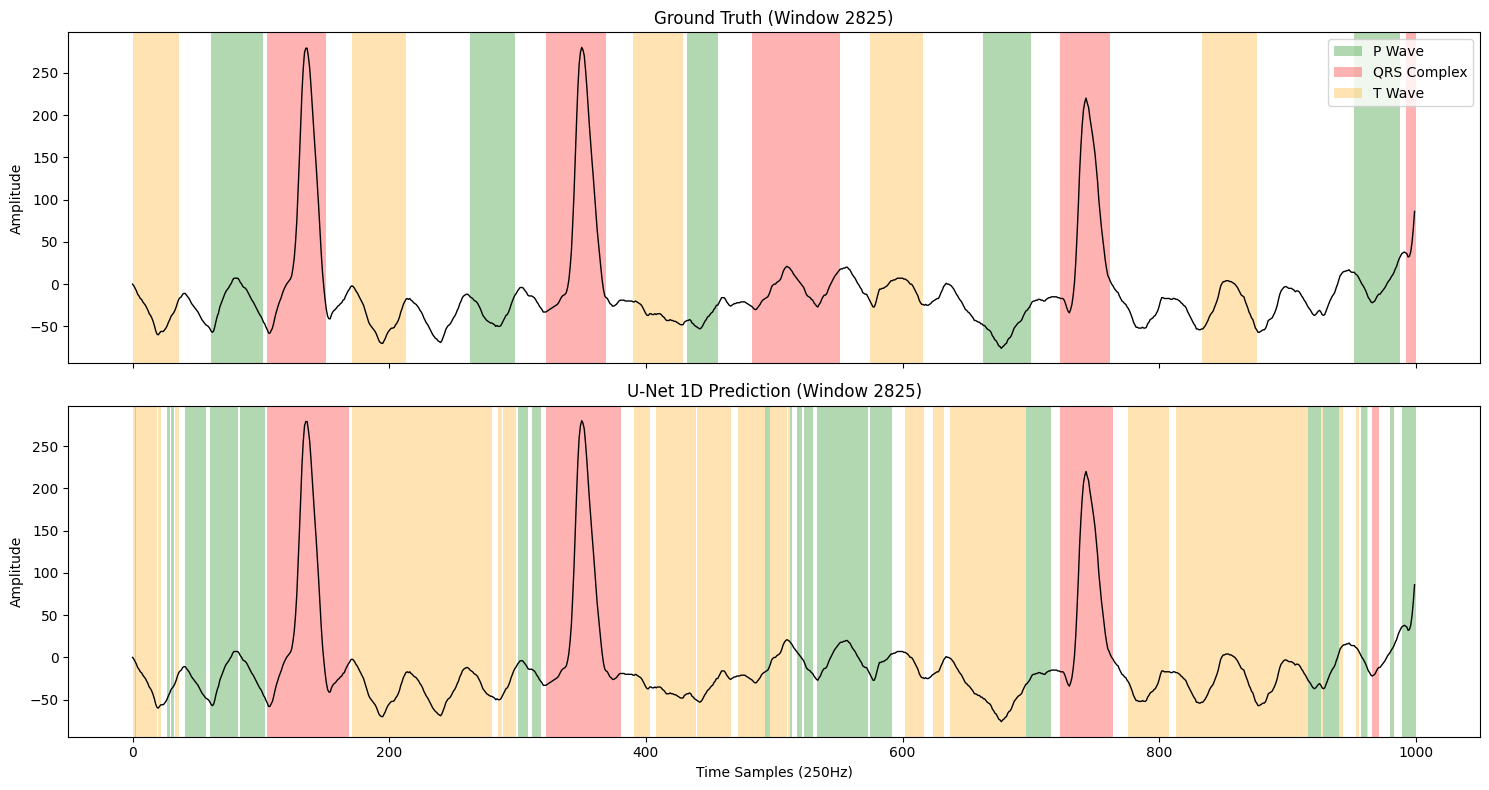

In [16]:
# ==========================================
# 13. Hard Example Mining
# ==========================================
import numpy as np

print("Calcolo dell'accuratezza locale per tutte le finestre del Test Set...")

# Calcoliamo l'accuracy per ogni singola finestra (N, 1000)
# y_pred_classes e y_test_classes sono shape (N, 1000)
window_accuracies = np.mean(y_pred_classes == y_test_classes, axis=1)

# Troviamo l'indice della finestra con l'accuratezza più bassa in assoluto
worst_idx = np.argmin(window_accuracies)
worst_accuracy = window_accuracies[worst_idx]

print(f"La finestra con le performance peggiori è l'indice {worst_idx} con una Accuracy del {worst_accuracy:.2%}")

# Generiamo il grafico comparativo utilizzando la funzione già definita nella Fase 8
# NOTA: Assicurati di aver eseguito la cella della Fase 8 in cui hai definito 'plot_ecg_segmentation' prima di lanciare questa!
plot_ecg_segmentation(X_test[worst_idx], y_test_classes[worst_idx], y_pred_classes[worst_idx], worst_idx)

**Failure Analysis:**
By isolating the worst-performing window, we can observe the typical scenarios that cause the 1D U-Net to fail. Such edge cases are usually characterized by severe signal artifacts, excessive baseline wander, or atypical ectopic beats where the morphological structure of the ECG is entirely corrupted.
In these specific windows, the network struggles to correctly anchor the spatial features, leading to fragmented segmentation or missed minority classes (like the P-Wave). This validates the need for potential future implementations of Attention mechanisms to better handle extreme morphological noise.